# SOLETE: Before and After Cleaning

Three views: missing data, sensor ranges, and a flagged day. All plots use **TRAIN only**.
Rules come from the main pipeline; no interpolation, target correction, or training is performed.
See [cleaning rules](cleaning_workflow.md).


In [1]:
from copy import deepcopy
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'eda':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import load_config
from src.data import load_data, partition_bounds
from src.cleaning import clean_training_data, TRAINING_COLUMNS

config = load_config(ROOT / 'config/config.yaml')
settings = deepcopy(config['data'])
settings['sensor_cleaning'] = False
raw = load_data(settings)
cleaned, flags = clean_training_data(raw)
_, start, end = partition_bounds(raw, settings)[0]
before = raw.iloc[start:end][list(TRAINING_COLUMNS)]
after = cleaned.iloc[start:end][list(TRAINING_COLUMNS)]
train_flags = flags.iloc[start:end]
labels = ['Power', 'Air temp.', 'Humidity', 'Wind speed', 'Wind direction', 'GHI', 'POA']
colors = {'Before': '#64748b', 'After': '#0f766e', 'Removed': '#c2410c'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})


## 1. Missing observations

Invalid sensor values become missing; the time grid stays intact. Review-only flags do not remove data.


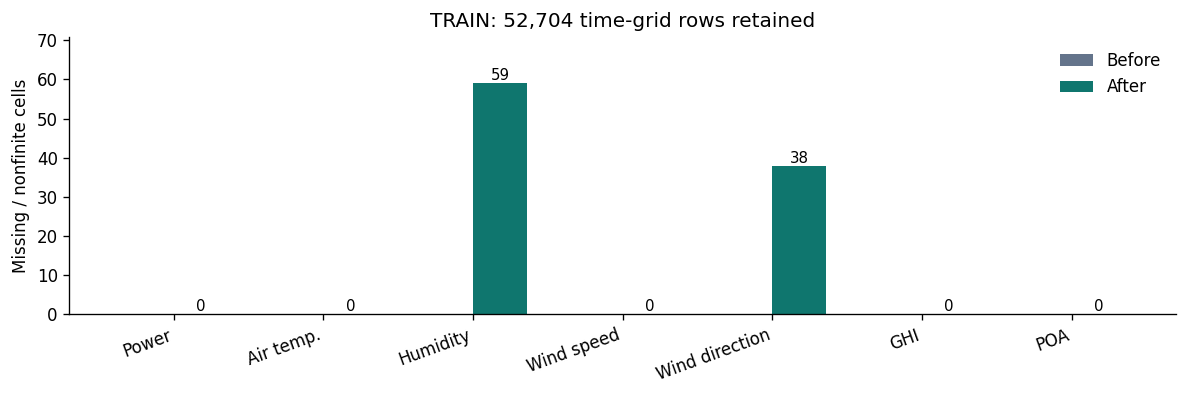

In [2]:
missing_before = (~np.isfinite(before)).sum()
missing_after = (~np.isfinite(after)).sum()
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(x - .18, missing_before, width=.36, label='Before', color=colors['Before'])
ax.bar(x + .18, missing_after, width=.36, label='After', color=colors['After'])
for position, count in enumerate(missing_after):
    ax.text(position + .18, count, str(count), ha='center', va='bottom', fontsize=9)
ax.set_xticks(x, labels, rotation=20, ha='right')
ax.set(ylabel='Missing / nonfinite cells', title=f'TRAIN: {len(before):,} time-grid rows retained')
ax.margins(y=.2)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)


## 2. Sensor ranges

Humidity is stored as a fraction. Valid wind direction is 0–360°; exactly 360° becomes 0°.
Orange points are invalidated readings. Calm wind alone remains valid; joint zero wind/humidity is removed.


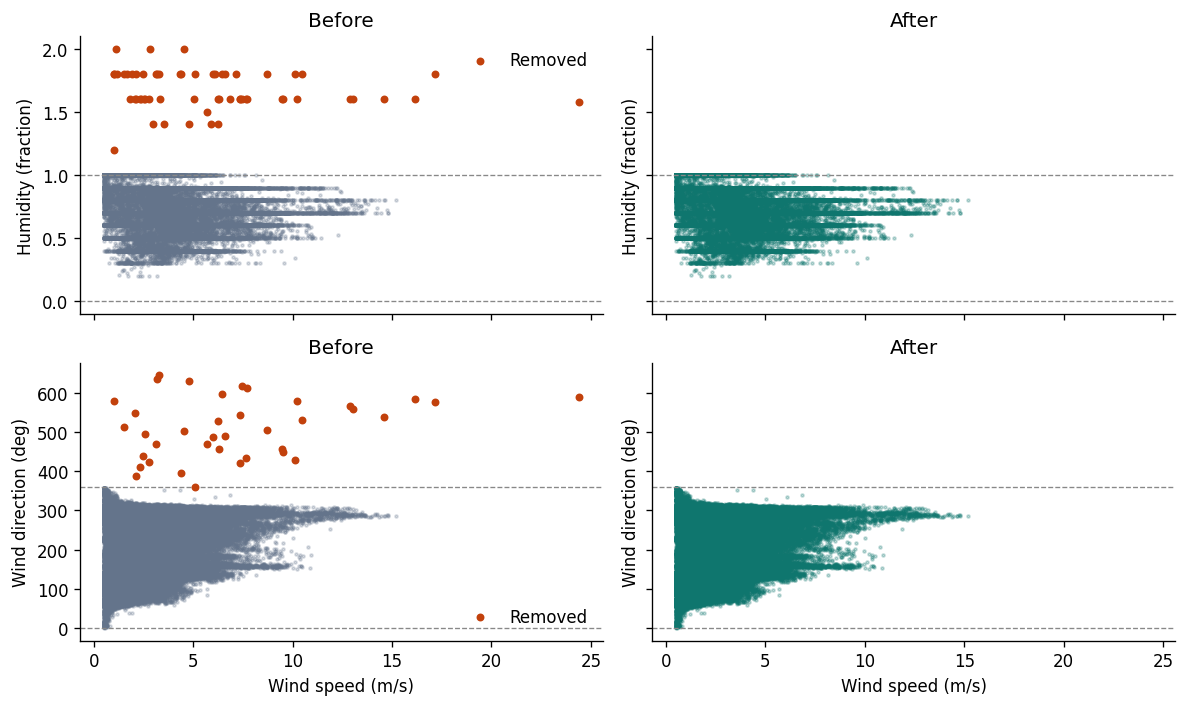

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey='row')
for row, (column, label, bounds) in enumerate([
    ('HUMIDITY[%]', 'Humidity (fraction)', (0, 1)),
    ('WIND_DIR[deg]', 'Wind direction (deg)', (0, 360)),
]):
    removed = (train_flags[column] & 7) != 0
    for col, (name, frame) in enumerate([('Before', before), ('After', after)]):
        ax = axes[row, col]
        ax.scatter(frame['WIND_SPEED[m1s]'], frame[column], s=3,
                   alpha=.25, color=colors[name], rasterized=True)
        if name == 'Before':
            ax.scatter(before.loc[removed, 'WIND_SPEED[m1s]'], before.loc[removed, column],
                       s=14, color=colors['Removed'], label='Removed', zorder=3)
        for bound in bounds:
            ax.axhline(bound, color='#888888', linestyle='--', linewidth=.8)
        ax.set(title=name, ylabel=label)
        if row == 1:
            ax.set_xlabel('Wind speed (m/s)')
    axes[row, 0].legend(frameon=False, loc='best')
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. A flagged day

Show the TRAIN day with the most invalidated sensor cells and its neighbors. Gaps are preserved;
orange crosses mark removed values. This diagnostic example is not a representative performance test.


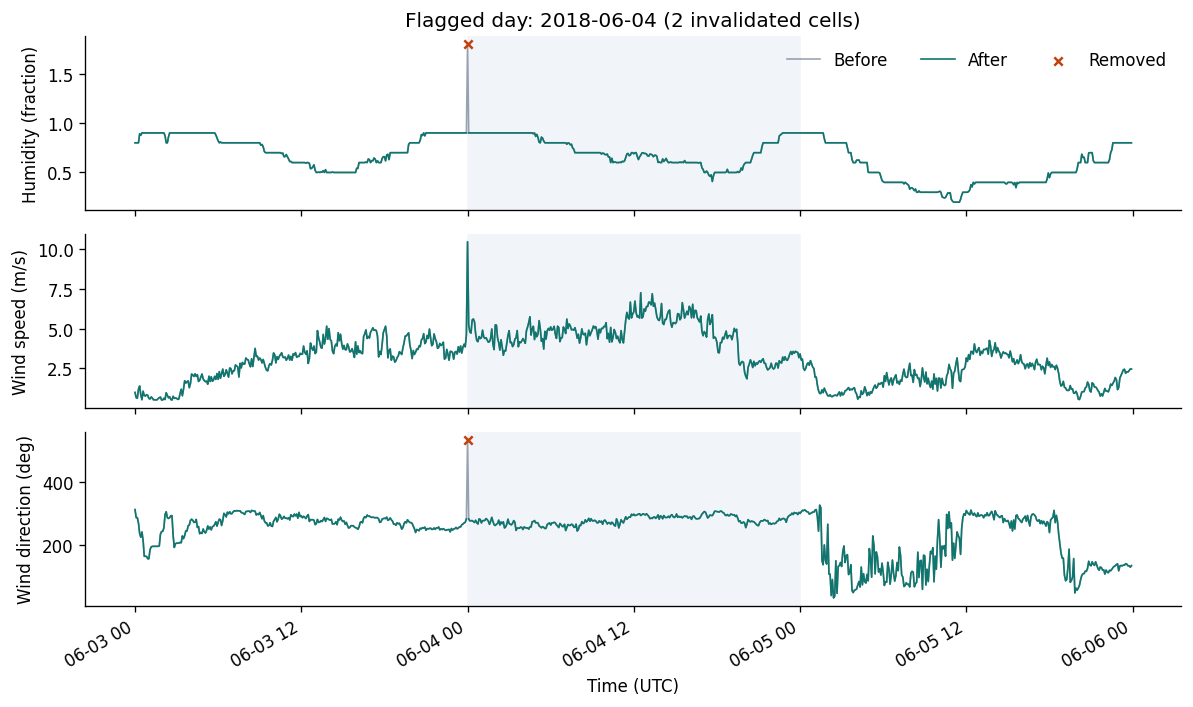

In [4]:
invalid = (train_flags & 7) != 0
daily_counts = invalid.sum(axis=1).resample('D').sum()
if daily_counts.max() > 0:
    day = daily_counts.idxmax()
    window = (before.index >= day - pd.Timedelta(days=1)) & (before.index < day + pd.Timedelta(days=2))
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for ax, column, label in zip(axes,
        ['HUMIDITY[%]', 'WIND_SPEED[m1s]', 'WIND_DIR[deg]'],
        ['Humidity (fraction)', 'Wind speed (m/s)', 'Wind direction (deg)']):
        ax.plot(before.index[window], before.loc[window, column], color=colors['Before'],
                alpha=.65, linewidth=1, label='Before')
        ax.plot(after.index[window], after.loc[window, column], color=colors['After'],
                linewidth=1, label='After')
        removed = window & invalid[column]
        ax.scatter(before.index[removed], before.loc[removed, column], marker='x',
                   color=colors['Removed'], s=25, label='Removed', zorder=3)
        ax.set_ylabel(label)
        ax.axvspan(day, day + pd.Timedelta(days=1), color='#f1f5f9', zorder=0)
    axes[0].set_title(f'Flagged day: {day:%Y-%m-%d} ({int(daily_counts.max())} invalidated cells)')
    axes[0].legend(frameon=False, ncol=3)
    axes[-1].set_xlabel('Time (UTC)')
    fig.autofmt_xdate()
    fig.tight_layout()
    display(fig)
    plt.close(fig)
else:
    print('No invalidated TRAIN observations; no flagged-day plot needed.')


**Scope:** These plots check cleaning effects, not forecast accuracy. Measured power is not replaced by Pac.
Physical target correction remains a separate training configuration choice.
